# Canteen Food Demand Forecasting with a Stacking Ensemble

This notebook forecasts daily meals sold at a university student canteen using `datasets/canteen_sales_2025_2026.xlsx`. It compares six models: Random Forest, XGBoost, SVR, LSTM, and two stacking ensembles that combine them through a Ridge regression meta-learner.

| Section | Content |
|---|---|
| 0 | Setup: dataset location, libraries, configuration |
| 1 | Data loading and integrity checks |
| 2 | Feature engineering: date features and lagged sales |
| 3 | Data analysis |
| 4 | One-hot encoding, train/test split, scaling |
| 5 | Evaluation metrics |
| 6 | Random Forest, XGBoost and SVR with grid search |
| 7 | LSTM |
| 8 | Stacking 1: RF + XGBoost + SVR → Ridge |
| 9 | Stacking 2: RF + XGBoost + SVR + LSTM → Ridge |
| 10 | Results and plots |

## 0. Setup
This section locates the dataset, imports the libraries and sets the configuration used throughout the notebook.

In [1]:
# Locate the dataset. Move to the repository's main folder (the folder that holds datasets/), so the paths below
# work wherever the notebook is opened. On Google Colab, where the repository is not present yet, it is cloned first.
import os, sys
from pathlib import Path
GITHUB_USER = "yklee7285"                     # GitHub account that hosts the public repository
REPO        = "food-demand-forecasting-fyp"
DATA_PATH   = "datasets/canteen_sales_2025_2026.xlsx"

root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets").is_dir()), None)
if root is not None:
    os.chdir(root)
elif "google.colab" in sys.modules:
    if not os.path.isdir(REPO):
        !git clone -q https://github.com/{GITHUB_USER}/{REPO}.git
    %cd {REPO}

In [2]:
# Standard library; hide warnings and TensorFlow start-up logs
import time, random, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# Data handling, plotting and statistical tests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# scikit-learn: splitting, tuning, scaling, models and metrics
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, r2_score
from xgboost import XGBRegressor

# TensorFlow / Keras for the LSTM
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
tf.get_logger().setLevel("ERROR")
sns.set_style("whitegrid")

# ---------------- Configuration ----------------
RANDOM_STATE      = 42        # seed for the train/test split and the tree models
TEST_SIZE         = 0.20      # share of days held out for testing
CV_FOLDS          = 5         # folds for grid-search cross-validation and stacking
SCORING           = "neg_mean_absolute_error"   # grid search keeps the parameters with the lowest MAE
SEQ_LEN           = 10        # LSTM input length: the 10 preceding operating days
WEEK_DAYS         = 6         # one operating week (Monday-Saturday) for the weekly lag
USE_NET_PRICE     = True      # include Net_price as a model input
LSTM_SCALE_TARGET = True      # LSTM learns a 0-1 scaled target; predictions are converted back to meals
SVR_TARGET_SD     = 9.63      # SVR learns the target rescaled to this standard deviation; predictions are converted back to meals
RIDGE_GRID        = {"alpha": [0.01, 0.1, 1, 10, 100]}   # candidate regularisation strengths for the Ridge meta-learner
TARGET            = "Quantity_sold"                     # column being forecast

def set_seeds(seed=RANDOM_STATE):
    # Fix the Python, NumPy and TensorFlow random generators so results are repeatable
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed)
set_seeds()

I0000 00:00:1795069533.320308     159 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795069548.335941     159 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Data loading and checks
This loads the dataset, sorts it by date and prints basic integrity checks. Each printed value should match its "expect" value.

In [3]:
df = pd.read_excel(DATA_PATH)
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df = df.sort_values("Timestamp").reset_index(drop=True)      # lag features and LSTM windows rely on chronological order

# Integrity checks: each printed value should match its "expect" value
print("Rows:", len(df), "| Range:", df.Timestamp.min().date(), "to", df.Timestamp.max().date())
print("Duplicates (expect 0):", df.Timestamp.duplicated().sum(), "| Missing values (expect 0):", df.isna().sum().sum())
print("Sundays (expect 0):", (df.Timestamp.dt.dayofweek == 6).sum())
print("Net_price mismatches (expect 0):", ((df[TARGET] * df.Price_per_meal - df.Net_price).abs() > 0.01).sum())
print("Mean quantity (expect ~6,440):", round(df[TARGET].mean(), 1))
display(df.head())

Rows: 626 | Range: 2025-01-01 to 2026-12-31
Duplicates (expect 0): 0 | Missing values (expect 0): 0
Sundays (expect 0): 0
Net_price mismatches (expect 0): 0
Mean quantity (expect ~6,440): 6422.6


,Timestamp,Day_of_Week,Weekend_Status,Academic_Period,Quantity_sold,Price_per_meal,Net_price
0,2025-01-01,Wednesday,Weekday,Teaching,7728,18.43,142427.04
1,2025-01-02,Thursday,Weekday,Teaching,6916,15.07,104224.12
2,2025-01-03,Friday,Weekday,Teaching,7997,8.56,68454.32
3,2025-01-04,Saturday,Weekend,Teaching,4340,17.79,77208.60
4,2025-01-06,Monday,Weekday,Teaching,6366,10.22,65060.52


## 2. Feature engineering
This adds model inputs derived from the date and from past sales:
* `Month`: month name.
* `Quantity_last_day`: meals sold on the previous operating day (Saturday's sales for a Monday).
* `Quantity_last_two_days`: total meals sold over the previous 2 operating days.
* `Quantity_last_week`: total meals sold over the previous 6 operating days (one Monday–Saturday week).

`Week_of_Month` is created only for the check in Section 3 and is not a model input. The first rows have no sales history for the lags, so those gaps are filled with each lag column's mean.

In [4]:
df["Month"]         = df.Timestamp.dt.month_name()
df["Week_of_Month"] = (df.Timestamp.dt.day - 1) // 7 + 1           # 1-5; used only for the check in Section 3

# Lagged sales: shifting by one row first ensures a day's own sales never enter its lags
past = df[TARGET].shift(1)                                          # previous operating day
df["Quantity_last_day"]      = past
df["Quantity_last_two_days"] = past.rolling(2).sum()
df["Quantity_last_week"]     = past.rolling(WEEK_DAYS).sum()

# Fill the first rows (no history yet) with each lag column's mean
LAG_COLS = ["Quantity_last_day", "Quantity_last_two_days", "Quantity_last_week"]
print("Imputed values:", df[LAG_COLS].isna().sum().to_dict())
df[LAG_COLS] = df[LAG_COLS].fillna(df[LAG_COLS].mean())
display(df[["Timestamp", "Day_of_Week", TARGET] + LAG_COLS].head(8))

Imputed values: {'Quantity_last_day': 1, 'Quantity_last_two_days': 2, 'Quantity_last_week': 6}


,Timestamp,Day_of_Week,Quantity_sold,Quantity_last_day,Quantity_last_two_days,Quantity_last_week
0,2025-01-01,Wednesday,7728,6421.3392,12838.330128,38498.198387
1,2025-01-02,Thursday,6916,7728.0000,12838.330128,38498.198387
2,2025-01-03,Friday,7997,6916.0000,14644.000000,38498.198387
3,2025-01-04,Saturday,4340,7997.0000,14913.000000,38498.198387
4,2025-01-06,Monday,6366,4340.0000,12337.000000,38498.198387
5,2025-01-07,Tuesday,6758,6366.0000,10706.000000,38498.198387
6,2025-01-08,Wednesday,7621,6758.0000,13124.000000,40105.000000
7,2025-01-09,Thursday,7353,7621.0000,14379.000000,39998.000000


## 3. Data analysis
This plots how meals sold vary with the main inputs, then tests whether week of the month has any effect on sales. The test is a one-way ANOVA: p > 0.05 means no meaningful effect, so week of the month is not used as an input.

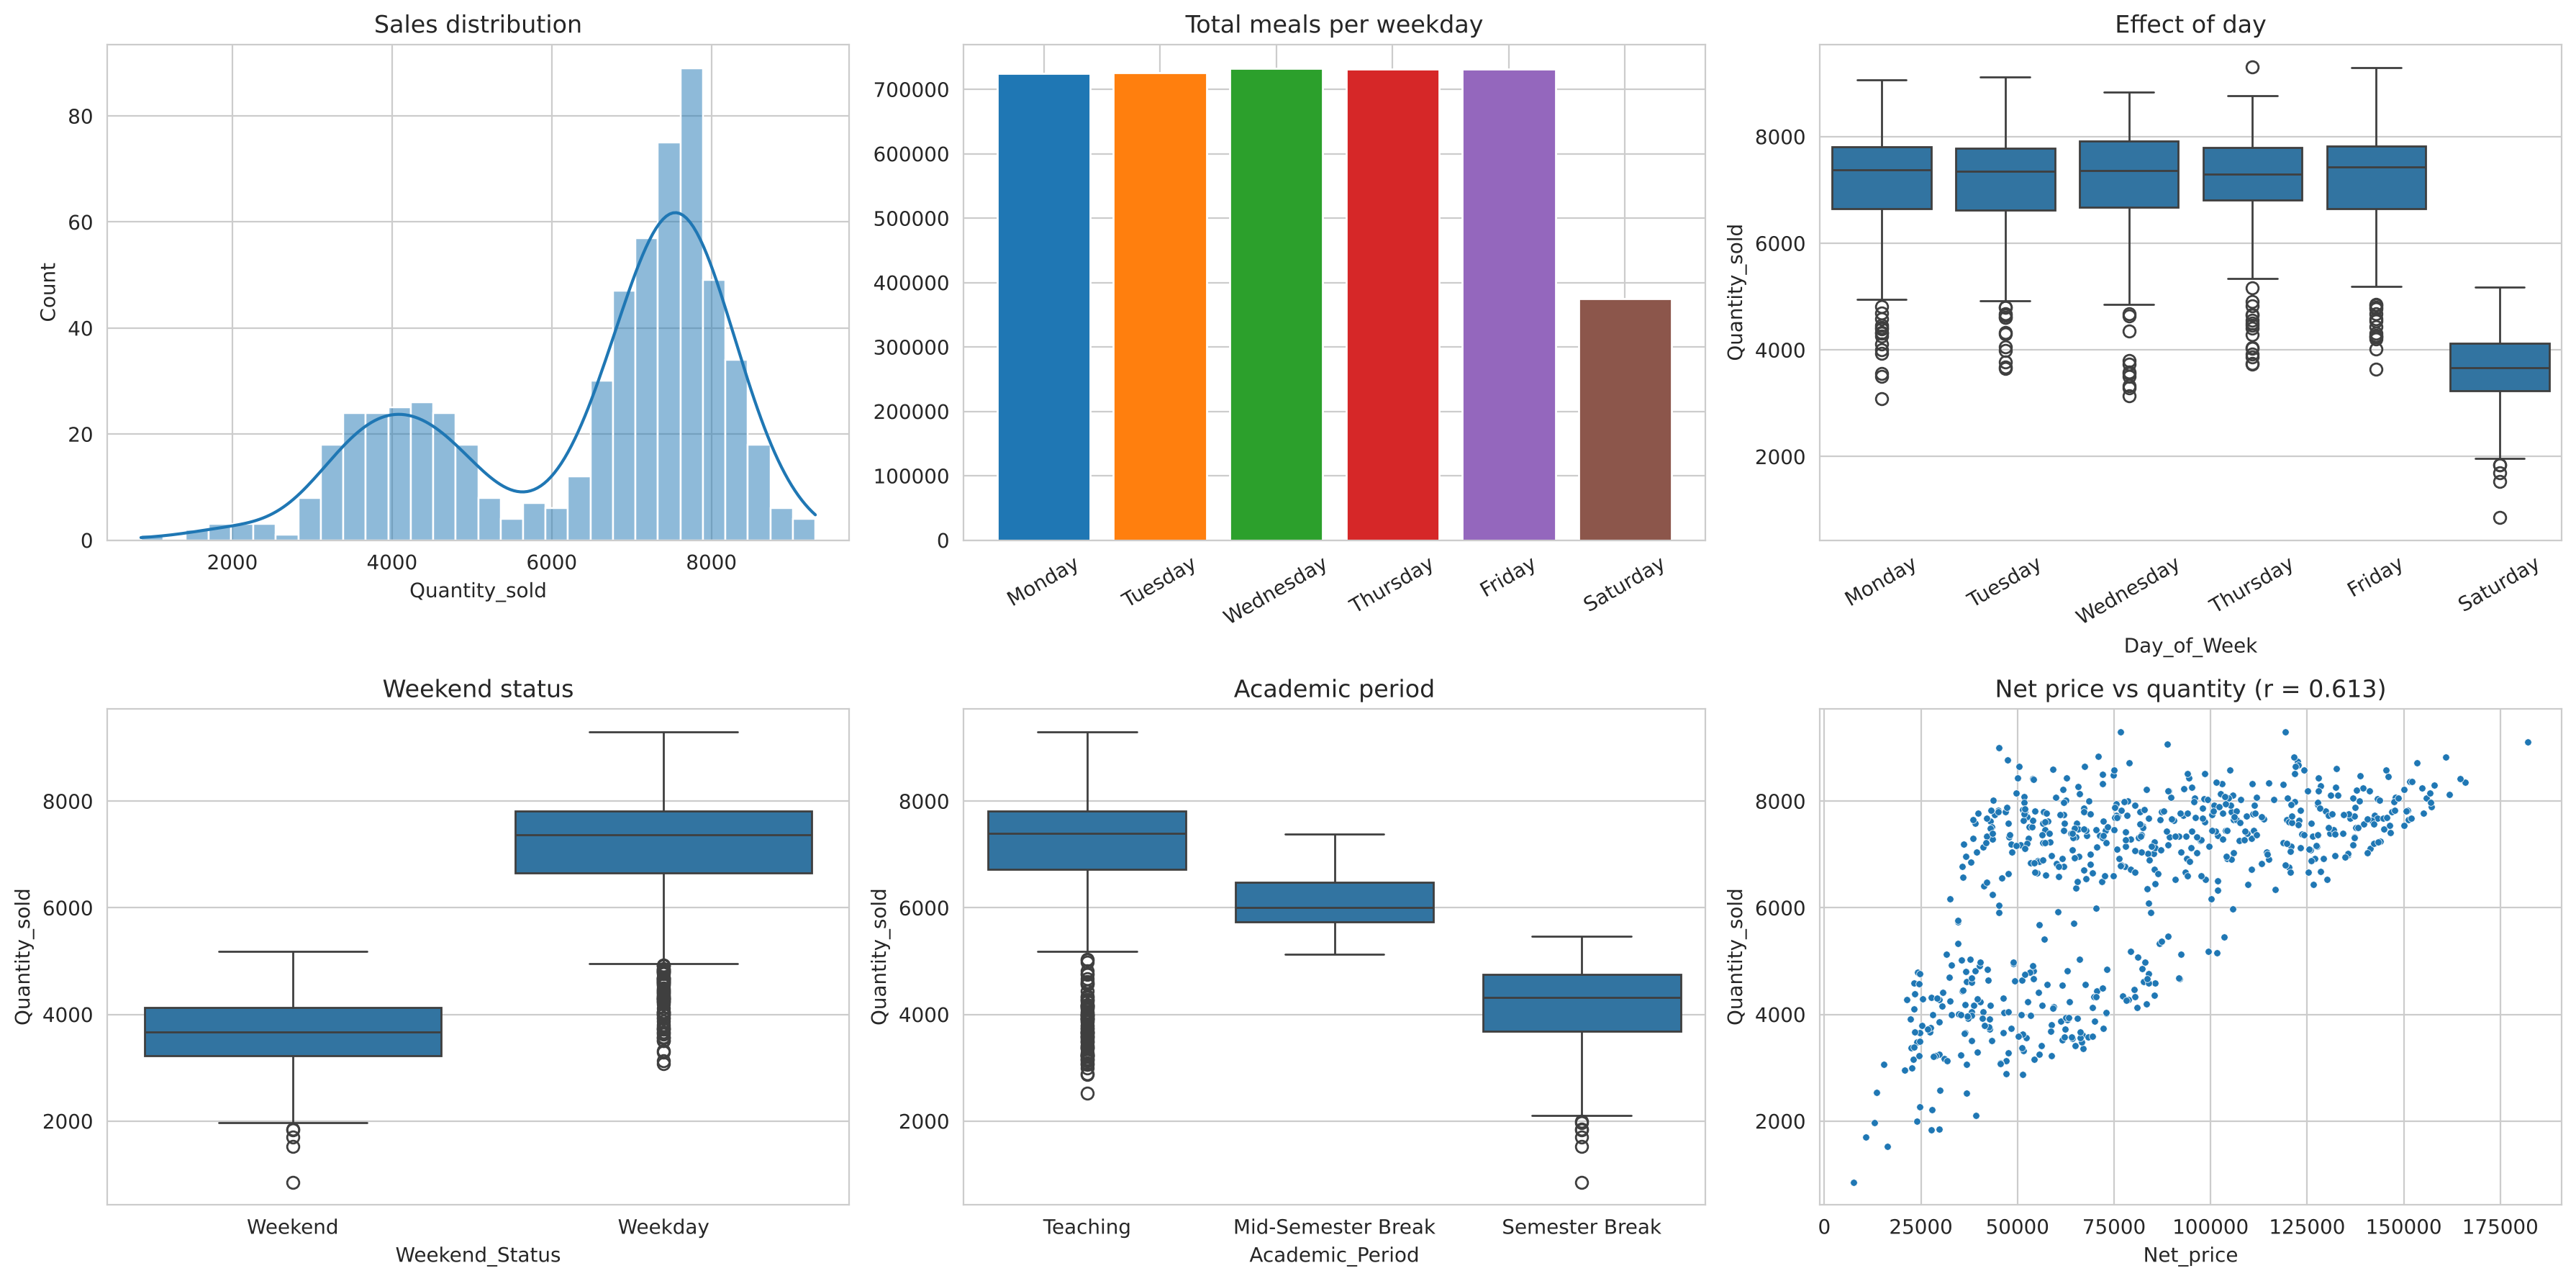

Week-of-month ANOVA: F = 0.387, p = 0.818 -> excluded (no meaningful effect)


In [5]:
DAYS    = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]
PERIODS = ["Teaching", "Mid-Semester Break", "Semester Break"]
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
# Distribution of daily meals sold
sns.histplot(df[TARGET], bins=30, kde=True, ax=ax[0, 0]).set_title("Sales distribution")
# Total meals sold on each weekday
ax[0, 1].bar(DAYS, df.groupby("Day_of_Week")[TARGET].sum().reindex(DAYS), color=sns.color_palette("tab10", 6))
ax[0, 1].set_title("Total meals per weekday"); ax[0, 1].tick_params(axis="x", rotation=30)
# Daily meals by weekday, weekend status and academic period
sns.boxplot(data=df, x="Day_of_Week", y=TARGET, order=DAYS, ax=ax[0, 2]).set_title("Effect of day")
ax[0, 2].tick_params(axis="x", rotation=30)
sns.boxplot(data=df, x="Weekend_Status", y=TARGET, order=["Weekend", "Weekday"], ax=ax[1, 0]).set_title("Weekend status")
sns.boxplot(data=df, x="Academic_Period", y=TARGET, order=PERIODS, ax=ax[1, 1]).set_title("Academic period")
# Net price against quantity, with their correlation in the title
sns.scatterplot(data=df, x="Net_price", y=TARGET, s=12, ax=ax[1, 2]).set_title(
    f"Net price vs quantity (r = {df[['Net_price', TARGET]].corr().iloc[0, 1]:.3f})")
plt.tight_layout(); plt.show()

# One-way ANOVA: does mean sales differ between weeks of the month?
f, p = stats.f_oneway(*[g[TARGET].values for _, g in df.groupby("Week_of_Month")])
print(f"Week-of-month ANOVA: F = {f:.3f}, p = {p:.3f} -> {'excluded (no meaningful effect)' if p > 0.05 else 'significant'}")

## 4. Encoding, split and scaling
1. Categorical inputs are one-hot encoded (one 0/1 column per category).
2. Days are split at random into 80 % training and 20 % testing. The split is made on row numbers rather than on the data itself, so Stacking 2 can look up each day’s 10-day LSTM window and use exactly the same training and test days as the other models.
3. Inputs are scaled to 0–1 with a scaler fitted on the training rows only, so no test information enters training. The target stays in meals.

In [6]:
CAT_COLS = ["Day_of_Week", "Month", "Weekend_Status", "Academic_Period"]
NUM_COLS = ["Price_per_meal"] + (["Net_price"] if USE_NET_PRICE else []) + LAG_COLS

X = pd.get_dummies(df[CAT_COLS + NUM_COLS], columns=CAT_COLS, dtype=float)    # one-hot encode the categorical columns
y = df[TARGET].to_numpy(dtype=float)

# Random 80/20 split on row positions, so LSTM windows can use the same rows
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, random_state=RANDOM_STATE)

# Fit the scaler on training predictors only, then apply it to every row
scaler = MinMaxScaler().fit(X.iloc[idx_tr])
X_all  = scaler.transform(X)
X_tr, X_te, y_tr, y_te = X_all[idx_tr], X_all[idx_te], y[idx_tr], y[idx_te]
print(f"{X.shape[1]} inputs | train {X_tr.shape} | test {X_te.shape}")
print(list(X.columns))

28 inputs | train (500, 28) | test (126, 28)
['Price_per_meal', 'Net_price', 'Quantity_last_day', 'Quantity_last_two_days', 'Quantity_last_week', 'Day_of_Week_Friday', 'Day_of_Week_Monday', 'Day_of_Week_Saturday', 'Day_of_Week_Thursday', 'Day_of_Week_Tuesday', 'Day_of_Week_Wednesday', 'Month_April', 'Month_August', 'Month_December', 'Month_February', 'Month_January', 'Month_July', 'Month_June', 'Month_March', 'Month_May', 'Month_November', 'Month_October', 'Month_September', 'Weekend_Status_Weekday', 'Weekend_Status_Weekend', 'Academic_Period_Mid-Semester Break', 'Academic_Period_Semester Break', 'Academic_Period_Teaching']


## 5. Evaluation metrics
$MAE=\frac1n\sum|y-\hat y|$ · $MAPE=\frac{100}{n}\sum|\frac{y-\hat y}{y}|$ · $Accuracy=100-MAPE$ · $R^2=1-\frac{\sum(y-\hat y)^2}{\sum(y-\bar y)^2}$

`evaluate` turns one model's test predictions into a row of the results table. `results`, `preds` and `truth` collect every model's output for Section 10.

In [7]:
def evaluate(name, y_true, y_pred, secs):
    # One results-table row: error metrics (in meals / %), R2, training time and test-set size
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {"Model": name, "MAE": mean_absolute_error(y_true, y_pred), "MAPE (%)": mape,
            "Accuracy (%)": 100 - mape, "R2": r2_score(y_true, y_pred), "Training time (s)": secs,
            "Test rows": len(y_true)}
results, preds, truth = [], {}, {}      # metric rows, test predictions and matching actual values per model

## 6. Individual models: Random Forest, XGBoost, SVR
Each model is tuned by 5-fold grid search on the training set (lowest MAE wins), refitted on all training rows, and evaluated on the test set. The training time covers both the search and the refit. SVR is wrapped so that it learns the target rescaled to a standard deviation of `SVR_TARGET_SD`; its predictions are converted back to meals.

In [8]:
svr_k = y_tr.std() / SVR_TARGET_SD     # factor that rescales the training target to SVR_TARGET_SD

GRIDS = {   # each model with its candidate hyperparameter values
    "RF":      (RandomForestRegressor(random_state=RANDOM_STATE),
                {"n_estimators": [50, 100], "max_depth": [5, 10, 20, None], "min_samples_split": [2, 5]}),
    "XGBoost": (XGBRegressor(random_state=RANDOM_STATE, n_jobs=1),
                {"n_estimators": [50, 100], "learning_rate": [0.05, 0.1, 0.2], "max_depth": [3, 5, 7]}),
    # SVR (default RBF kernel and gamma) learns the target divided by svr_k; predictions are multiplied back to meals
    "SVR":     (TransformedTargetRegressor(SVR(), func=lambda v: v / svr_k, inverse_func=lambda v: v * svr_k),
                {"regressor__C": [0.1, 1], "regressor__epsilon": [0.1, 0.2]}),
}
best = {}   # tuned model per name, reused by the stacking ensembles
for name, (est, grid) in GRIDS.items():
    # Grid search with 5-fold CV, then refit of the best setting on all training rows (timed together)
    t0 = time.time()
    gs = GridSearchCV(est, grid, cv=CV_FOLDS, scoring=SCORING, n_jobs=-1).fit(X_tr, y_tr)
    secs = time.time() - t0
    best[name], preds[name], truth[name] = gs.best_estimator_, gs.predict(X_te), y_te
    results.append(evaluate(name, y_te, preds[name], secs))
    print(f"{name:8s} {gs.best_params_}  ({secs:.1f}s)")

RF       {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}  (6.9s)


XGBoost  {'learning_rate': 0.2, 'max_depth': 7, 'n_estimators': 100}  (2.6s)
SVR      {'regressor__C': 1, 'regressor__epsilon': 0.2}  (0.2s)


## 7. LSTM
Each sample is a window of the **10 preceding operating days** (all scaled inputs), and the label is the meals sold on the following day. The complete windows are split 80/20 with the same seed. The test windows are passed as validation data, which only reports a score during training and does not change the model.

In [9]:
def build_lstm(n_features):
    # Two stacked LSTM layers (50 units each) with 20 % dropout after each, then one output neuron
    model = Sequential([Input(shape=(SEQ_LEN, n_features)),
                        LSTM(50, return_sequences=True), Dropout(0.2),
                        LSTM(50, return_sequences=False), Dropout(0.2),
                        Dense(1)])
    model.compile(optimizer="adam", loss="mse")           # Adam with its default learning rate, mean squared error loss
    return model

class LSTMRegressor:
    # Wraps the Keras LSTM with optional 0-1 target scaling; predictions always come back in meals.
    def __init__(self, n_features, scale_target=LSTM_SCALE_TARGET):
        self.n_features, self.scale_target = n_features, scale_target
    def fit(self, W, y, validation_data=None):
        set_seeds()                                        # every LSTM starts from the same random state
        self.ys = MinMaxScaler().fit(y.reshape(-1, 1)) if self.scale_target else None
        f = (lambda v: self.ys.transform(v.reshape(-1, 1)).ravel()) if self.scale_target else (lambda v: v)
        val = None if validation_data is None else (validation_data[0], f(validation_data[1]))
        self.model = build_lstm(self.n_features)
        self.model.fit(W, f(y), epochs=20, batch_size=32, validation_data=val, verbose=0)
        return self
    def predict(self, W):
        p = self.model.predict(W, verbose=0)
        return (self.ys.inverse_transform(p) if self.scale_target else p).ravel()

def make_windows(days):
    # Window for day t = rows t-10 ... t-1. Rows before day 0 are padded by repeating day 0
    # (only Stacking 2 needs that, because it must predict every row).
    return np.stack([X_all[np.clip(np.arange(t - SEQ_LEN, t), 0, None)] for t in days])

# Complete windows only (days with 10 days of history), split 80/20 with the same seed
days = np.arange(SEQ_LEN, len(y))
W, yw = make_windows(days), y[days]
W_tr, W_te, yw_tr, yw_te = train_test_split(W, yw, test_size=TEST_SIZE, random_state=RANDOM_STATE)

# Train (timed), predict the test windows and record the metrics
t0 = time.time()
lstm = LSTMRegressor(W.shape[2]).fit(W_tr, yw_tr, validation_data=(W_te, yw_te))
secs = time.time() - t0
preds["LSTM"], truth["LSTM"] = lstm.predict(W_te), yw_te
results.append(evaluate("LSTM", yw_te, preds["LSTM"], secs))
print(f"LSTM trained in {secs:.1f}s")

LSTM trained in 7.6s


## 8. Stacking 1: RF + XGBoost + SVR → Ridge
The tuned RF, XGBoost and SVR models are combined with scikit-learn's `StackingRegressor`:
1. 5-fold cross-validation produces an out-of-fold prediction from each base model for every training row.
2. A Ridge regression learns how to weight those predictions. It sees only the predictions, not the original inputs.
3. The base models are refitted on all training rows.

Ridge's regularisation strength (`alpha`) is chosen by an outer 5-fold grid search, which rebuilds the whole stack for every candidate value.

In [10]:
t0 = time.time()
# Stack of the tuned base models with a Ridge meta-learner trained on 5-fold out-of-fold predictions
stack = StackingRegressor(estimators=[("rf", best["RF"]), ("xgb", best["XGBoost"]), ("svr", best["SVR"])],
                          final_estimator=Ridge(), cv=CV_FOLDS, passthrough=False, n_jobs=-1)
# Outer grid search over Ridge alpha; each candidate rebuilds and scores the whole stack
s1 = GridSearchCV(stack, {"final_estimator__" + k: v for k, v in RIDGE_GRID.items()},
                  cv=CV_FOLDS, scoring=SCORING).fit(X_tr, y_tr)
secs = time.time() - t0
preds["Stacking 1"], truth["Stacking 1"] = s1.predict(X_te), y_te
results.append(evaluate("Stacking 1 (RF, XGBoost, SVR)", y_te, preds["Stacking 1"], secs))
print(f"Stacking 1: {s1.best_params_} | Ridge weights [RF, XGB, SVR] = {np.round(s1.best_estimator_.final_estimator_.coef_, 3)} ({secs:.1f}s)")

Stacking 1: {'final_estimator__alpha': 0.01} | Ridge weights [RF, XGB, SVR] = [ 0.077  1.032 -0.13 ] (28.6s)


## 9. Stacking 2: RF + XGBoost + SVR + LSTM → Ridge
This uses the same stacking and grid-search procedure as Stacking 1, with the LSTM added as a fourth base model.
* Each row's input is `[day features | flattened 10-day window]`. Column selectors give RF, XGBoost and SVR the day features only, and the LSTM the window only.
* With `STACK2_LSTM_MODE = "prefit"`, the LSTM is trained once on the training rows (included in the training time) and reused inside every fold. `"refit"` trains a new LSTM in every fold instead, which takes about 15–20 minutes.
* The prefit LSTM has already seen the training rows, so the cell after the model compares its accuracy on those rows with its accuracy on unseen test rows.

In [11]:
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin
from sklearn.pipeline import Pipeline
from joblib import parallel_backend

STACK2_LSTM_MODE = "prefit"   # "prefit" = LSTM trained once and reused in every fold; "refit" = new LSTM trained in every fold
PREFIT_LSTM = {}              # the once-trained LSTM, looked up by key so sklearn's clone() never copies a Keras model

class ColumnSlice(TransformerMixin, BaseEstimator):
    # Keeps columns [start, stop) of the combined input.
    def __init__(self, start=0, stop=None):
        self.start, self.stop = start, stop
    def fit(self, Z, y=None):
        return self
    def transform(self, Z):
        return Z[:, self.start:self.stop]

class WindowLSTM(RegressorMixin, BaseEstimator):
    # LSTM base model for StackingRegressor; input = flattened 10-day windows.
    # With prefit_key, fit() only attaches the once-trained model; otherwise it trains a new LSTM.
    def __init__(self, n_features=1, prefit_key=None):
        self.n_features, self.prefit_key = n_features, prefit_key
    def _windows(self, Z):
        return Z.reshape(-1, SEQ_LEN, self.n_features)      # flat rows back to (samples, 10 days, features)
    def fit(self, Z, y):
        self.model_ = (PREFIT_LSTM[self.prefit_key] if self.prefit_key
                       else LSTMRegressor(self.n_features).fit(self._windows(Z), y))
        return self
    def predict(self, Z):
        return self.model_.predict(self._windows(Z))

# Combined input: the day's own features followed by its flattened 10-day window
p     = X_all.shape[1]
W_all = make_windows(np.arange(len(y)))                       # every row gets a window (first 10 padded)
Z_all = np.hstack([X_all, W_all.reshape(len(y), -1)])         # [day features | flattened window]
Z_tr, Z_te = Z_all[idx_tr], Z_all[idx_te]
on_day = lambda est: Pipeline([("day_features", ColumnSlice(0, p)), ("model", clone(est))])   # base model on day features only

t0 = time.time()
if STACK2_LSTM_MODE == "prefit":
    PREFIT_LSTM["stack2"] = LSTMRegressor(p).fit(W_all[idx_tr], y_tr)      # the single LSTM training
# LSTM base model on the window columns only
lstm_base = Pipeline([("window", ColumnSlice(p, None)),
                      ("model", WindowLSTM(p, "stack2" if STACK2_LSTM_MODE == "prefit" else None))])

# Same stacking set-up as Stacking 1, with the LSTM as a fourth base model
stack2 = StackingRegressor(
    estimators=[("rf", on_day(best["RF"])), ("xgb", on_day(best["XGBoost"])), ("svr", on_day(best["SVR"])), ("lstm", lstm_base)],
    final_estimator=Ridge(), cv=CV_FOLDS, passthrough=False, n_jobs=-1)     # base models fitted in parallel
# Threads instead of separate processes, so every worker shares the one in-memory Keras model
with parallel_backend("threading"):
    s2 = GridSearchCV(stack2, {"final_estimator__" + k: v for k, v in RIDGE_GRID.items()},
                      cv=CV_FOLDS, scoring=SCORING).fit(Z_tr, y_tr)
secs = time.time() - t0
preds["Stacking 2"], truth["Stacking 2"] = s2.predict(Z_te), y_te
results.append(evaluate("Stacking 2 (RF, XGBoost, SVR, LSTM)", y_te, preds["Stacking 2"], secs))
print(f"Stacking 2 ({STACK2_LSTM_MODE}): {s2.best_params_} | Ridge weights [RF, XGB, SVR, LSTM] = "
      f"{np.round(s2.best_estimator_.final_estimator_.coef_, 3)} ({secs:.1f}s)")

Stacking 2 (prefit): {'final_estimator__alpha': 0.01} | Ridge weights [RF, XGB, SVR, LSTM] = [ 0.074  1.037 -0.21   0.073] (46.1s)


In [12]:
# Prefit LSTM accuracy on the training rows it was trained on (whose predictions train Ridge) vs unseen test rows
if STACK2_LSTM_MODE == "prefit":
    m = PREFIT_LSTM["stack2"]
    tr_hat, te_hat = m.predict(W_all[idx_tr]), m.predict(W_all[idx_te])
    display(pd.DataFrame({"MAE (meals)": [mean_absolute_error(y_tr, tr_hat), mean_absolute_error(y_te, te_hat)],
                          "R2": [r2_score(y_tr, tr_hat), r2_score(y_te, te_hat)]},
                         index=["Training days (seen, fed to Ridge)", "Test days (unseen)"]).round(3))

,MAE (meals),R2
"Training days (seen, fed to Ridge)",578.936,0.817
Test days (unseen),669.135,0.688


## 10. Results
These are the test-set metrics for all six models. The LSTM is evaluated on its own 124 test windows; the other models on the 126 test days.

In [13]:
# Results table: one row per model
res = pd.DataFrame(results).set_index("Model")
display(res.round(3))

,MAE,MAPE (%),Accuracy (%),R2,Training time (s),Test rows
Model,,,,,,
RF,299.636,4.987,95.013,0.947,6.869,126
XGBoost,242.496,4.144,95.856,0.958,2.580,126
SVR,502.116,8.402,91.598,0.860,0.161,126
LSTM,665.656,12.323,87.677,0.763,7.648,124
"Stacking 1 (RF, XGBoost, SVR)",233.401,4.038,95.962,0.960,28.589,126
"Stacking 2 (RF, XGBoost, SVR, LSTM)",237.040,4.105,95.895,0.960,46.084,126


### Actual vs predicted
Left: each test prediction plotted against the actual value (red line = perfect prediction). Right: actual and predicted values across the test samples.

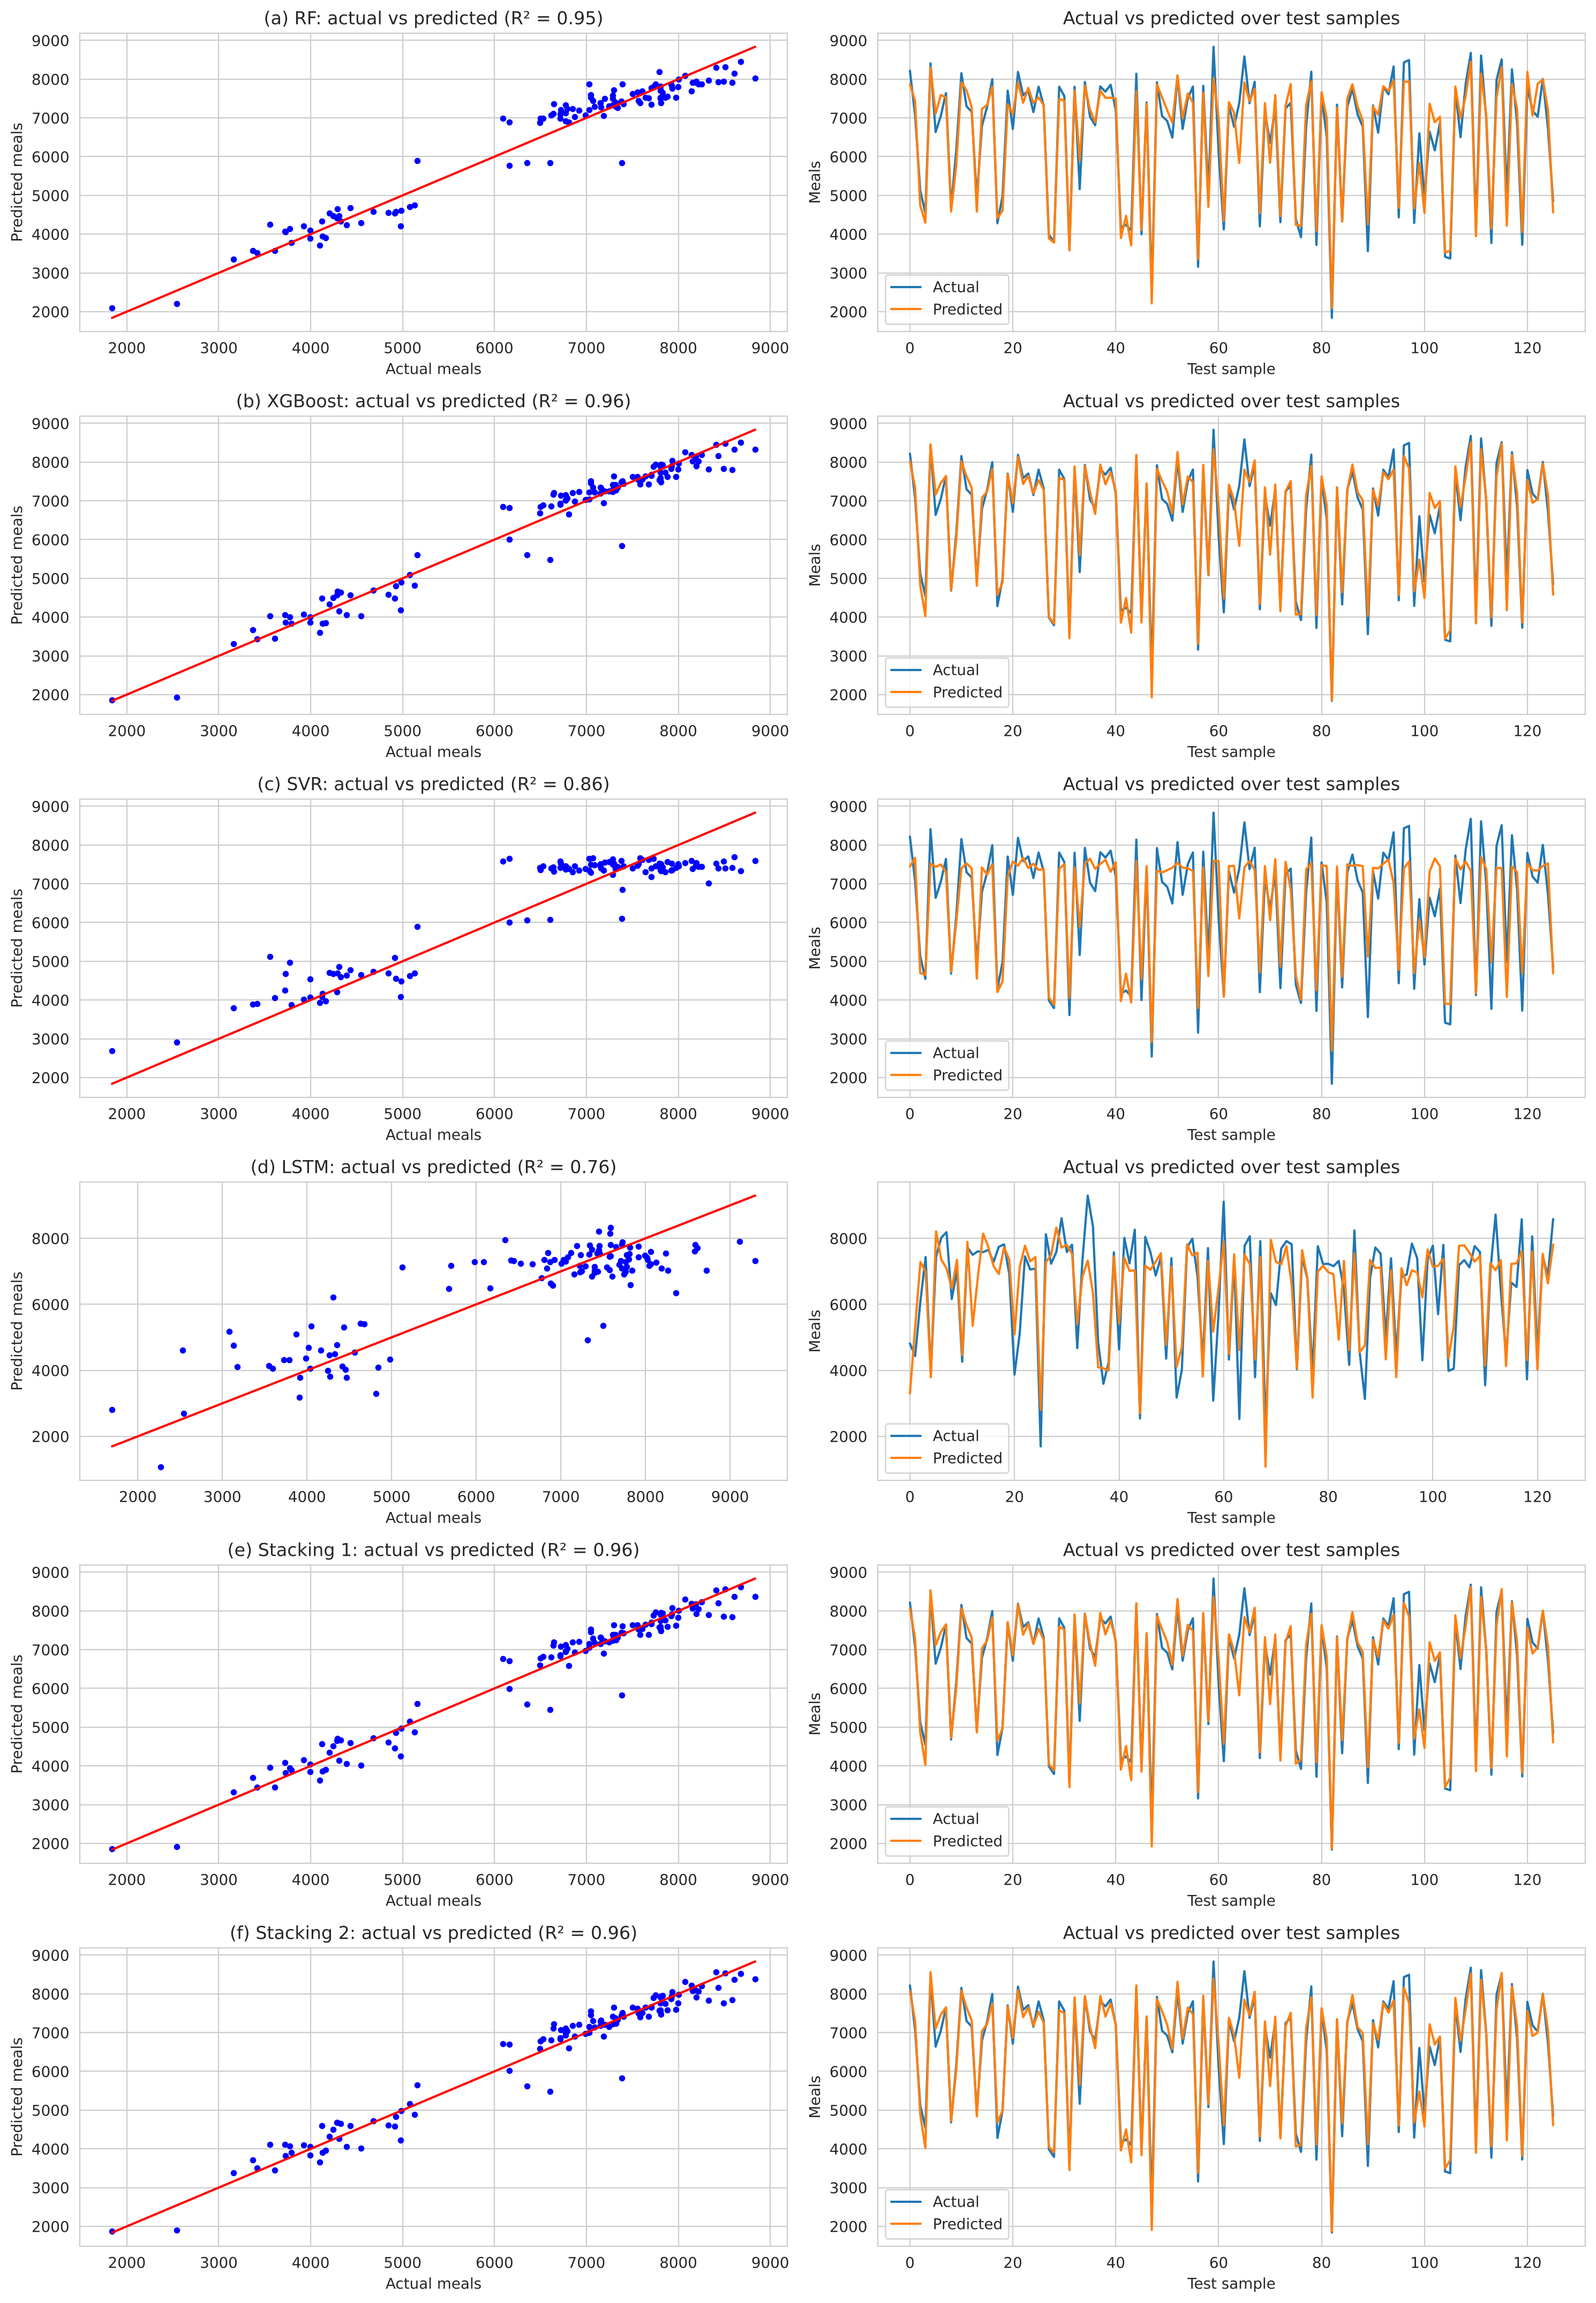

In [14]:
fig, axes = plt.subplots(len(preds), 2, figsize=(15, 3.6 * len(preds)))
for i, (name, p_) in enumerate(preds.items()):
    a = truth[name]; lims = [a.min(), a.max()]
    # Scatter of predicted vs actual with the identity line
    axes[i, 0].scatter(a, p_, s=10, c="blue"); axes[i, 0].plot(lims, lims, "r-")
    axes[i, 0].set(title=f"({'abcdef'[i]}) {name}: actual vs predicted (R² = {r2_score(a, p_):.2f})",
                   xlabel="Actual meals", ylabel="Predicted meals")
    # Actual and predicted series over the test samples
    axes[i, 1].plot(a, label="Actual"); axes[i, 1].plot(p_, label="Predicted")
    axes[i, 1].set(title="Actual vs predicted over test samples", xlabel="Test sample", ylabel="Meals"); axes[i, 1].legend()
plt.tight_layout(); plt.show()

### Accuracy vs training time
R² (higher is better) and training time for each model, with the value labelled on each bar.

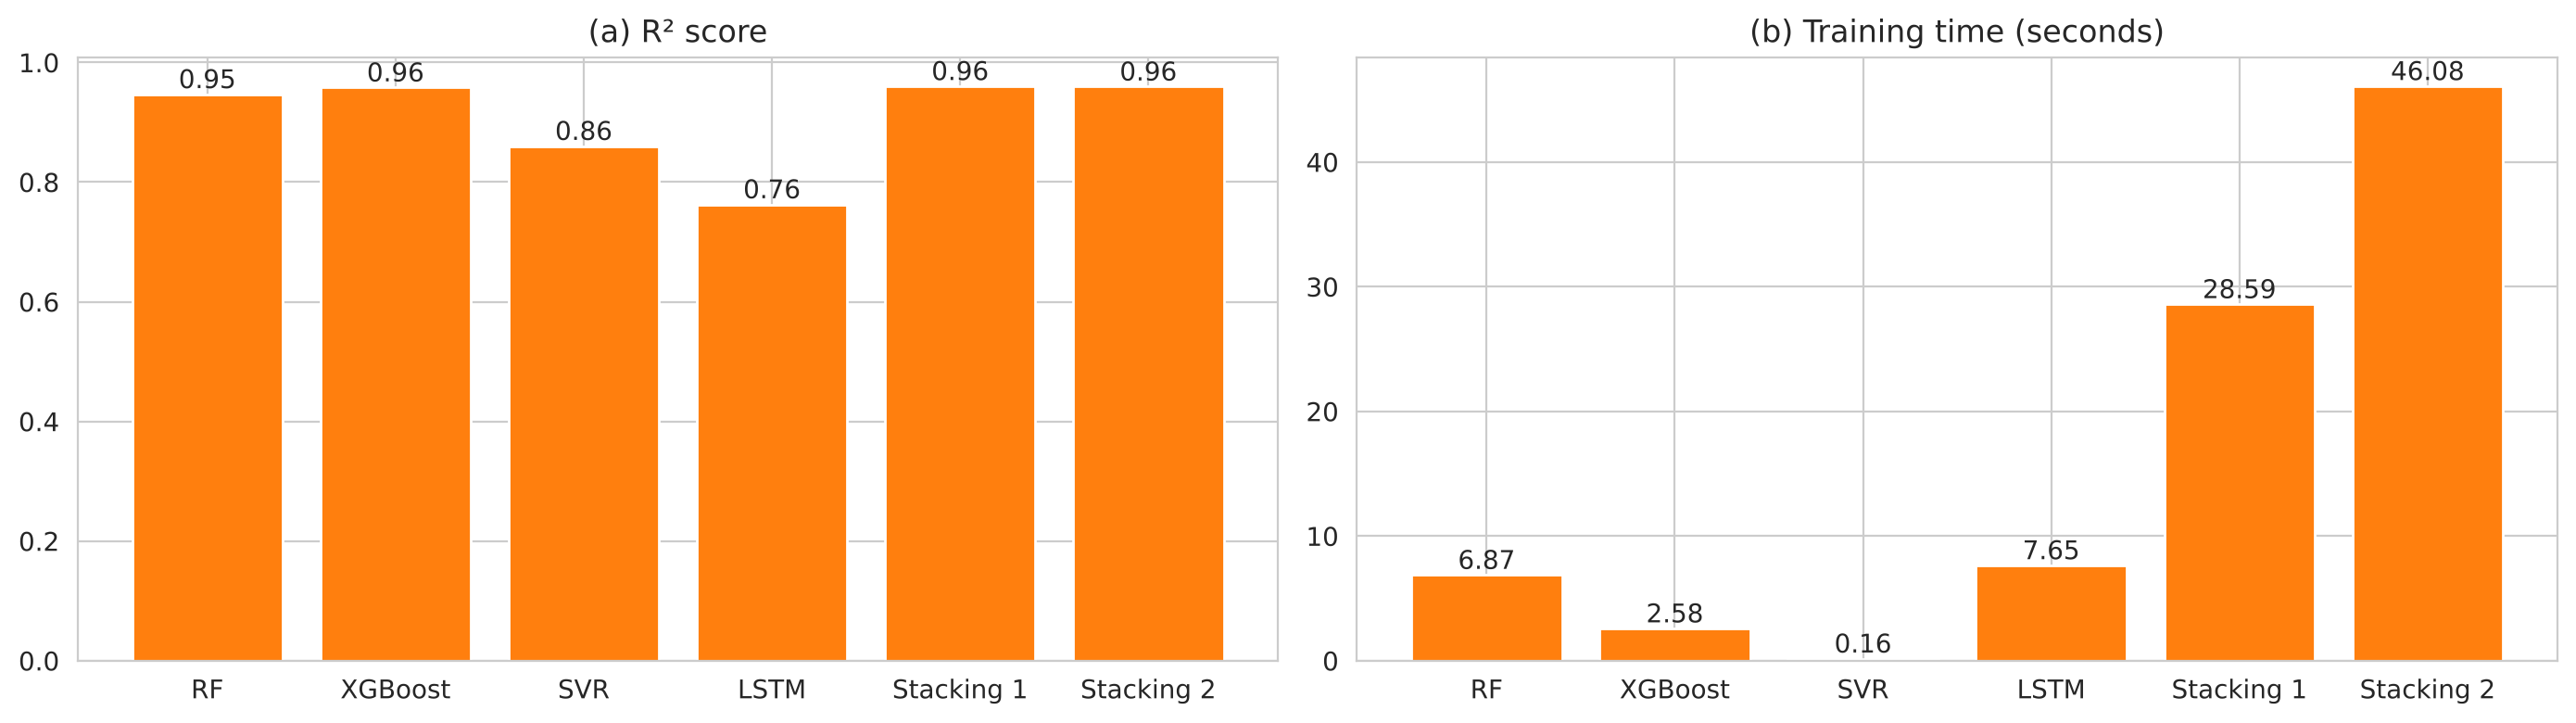

In [15]:
t = res.rename(index=lambda s: s.split(" (")[0])        # short model names for the x-axis
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, col, title in [(ax[0], "R2", "(a) R² score"), (ax[1], "Training time (s)", "(b) Training time (seconds)")]:
    a.bar(t.index, t[col], color="tab:orange"); a.set_title(title)
    for x, v in enumerate(t[col]): a.annotate(f"{v:.2f}", (x, v), ha="center", va="bottom")
plt.tight_layout(); plt.show()